## 🎯 A sua missão

Vocês vão construir um modelo de Inteligência Artificial que, olhando os sinais de cada
estudante, sinalize o **risco de evasão** em três níveis: **baixo**, **médio** ou **alto**.

A infraestrutura de código já está montada. O que se exige de vocês é o que não pode ser
automatizado: **decidir com critério, interpretar os resultados e reconhecer os limites do
que foi construído.**

Uma observação metodológica antes de começar. O problema que a Marina traz é de
**classificação supervisionada**: existe um conjunto de casos com resposta conhecida, e a
tarefa é induzir, a partir deles, uma regra que generalize para casos novos. A palavra
central aí é *generalizar*. Um modelo que reproduz perfeitamente o que já viu, mas falha
diante do que não viu, não tem valor prático. Boa parte das decisões de vocês neste caderno
existe para proteger essa capacidade de generalização.

### 🗺️ O mapa da operação

| Bloco | O que vocês fazem | Como |
|:---|:---|:---|
| **1 · EXPLORAR** | Conhecer os estudantes da Marina e procurar pistas | Só clicando |
| **2 · CONFIGURAR** | Decidir como o modelo vai aprender | Só arrastando |
| **3 · MODELAR** | Ensinar o modelo e fazer as previsões | ✏️ Completando o código |
| **4 · AVALIAR** | Descobrir se o farol funciona e o que ele enxerga | Só clicando |

> ⚠️ **Antes de começar:** vá em `Ambiente de execução` → `Alterar o tipo de ambiente de
> execução` e confirme que está em **CPU**. Esta operação inteira roda em segundos, sem
> precisar de placa de vídeo. É assim que garantimos que todas as equipes do Brasil
> compitam em pé de igualdade.
>
> Use `Arquivo` → `Salvar uma cópia no Drive` antes de começar, para não perder o trabalho.

In [18]:
#@title 🛠️ Preparação: carregando os dados da Marina { display-mode: "form" }
# Endereços oficiais dos dados. A organização republica aqui se precisar trocar.
URL_TREINO = "https://drive.google.com/uc?export=download&id=1j9hXiDzF-h6L6vBxT6fT_XQqy-eMkmVi"
URL_TESTE = "https://drive.google.com/uc?export=download&id=1qxYUo-M23BEtiQTAcMGUh8Tz4--qCzNx"

import pathlib, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

NOMES = {0: "Baixo", 1: "Médio", 2: "Alto"}
CORES = ["#3DCB55", "#FFC107", "#E6177A"]


def _carregar(url, nome_local):
    """Baixa do endereço oficial; se a rede falhar, usa cópia local ou pede envio."""
    print(f"Baixando {nome_local}...")
    try:
        return pd.read_csv(url)
    except Exception as erro:
        print(f"  não deu certo ({erro.__class__.__name__}).")
        if not pathlib.Path(nome_local).exists():
            from google.colab import files
            print(f"  envie o arquivo {nome_local}:")
            files.upload()
        return pd.read_csv(nome_local)


# Conjunto PÚBLICO: vocês têm as respostas. Serve para treinar e validar.
dados = _carregar(URL_TREINO, "treino.csv")

# Conjunto de TESTE: tamanho fixo, respostas ocultas. É contra ele que a
# plataforma compara a submissão de todas as equipes.
_teste = _carregar(URL_TESTE, "teste.csv")
IDS_TESTE = _teste["id_estudante"].to_numpy()
dados_teste = _teste.drop(columns=["id_estudante"])
N_TESTE = len(dados_teste)

print("Ambiente carregado.\n")
print(f"  Conjunto público (com respostas) .... {len(dados):>5} estudantes")
print(f"  Conjunto de teste (sem respostas) ... {len(dados_teste):>5} estudantes  [tamanho fixo]")
print(f"  Variáveis disponíveis ............... {dados.shape[1]-1}\n")
print("  O conjunto de teste tem tamanho FIXO e igual para todas as equipes.")
print("  A submissão de vocês precisará ter exatamente", N_TESTE, "linhas.\n")
display(dados.head())

Baixando treino.csv...
Baixando teste.csv...
Ambiente carregado.

  Conjunto público (com respostas) ....  3236 estudantes
  Conjunto de teste (sem respostas) ...  1078 estudantes  [tamanho fixo]
  Variáveis disponíveis ............... 35

  O conjunto de teste tem tamanho FIXO e igual para todas as equipes.
  A submissão de vocês precisará ter exatamente 1078 linhas.



,solteiro,genero,idade_na_matricula,escolaridade_mae,escolaridade_pai,ocupacao_mae,ocupacao_pai,bolsista,devedor,mensalidades_em_dia,...,curso_equinocultura,curso_gestao,curso_gestao_noturno,curso_higiene_oral,curso_jornalismo,curso_publicidade_marketing,curso_servico_social,curso_servico_social_noturno,curso_turismo,risco_evasao
0,1,0,31,1,1,1,1,1,0,1,...,0,0,0,0,0,0,0,1,0,0
1,0,0,42,0,0,1,1,0,1,0,...,0,1,0,0,0,0,0,0,0,2
2,1,0,19,0,1,3,2,1,0,1,...,0,0,0,0,0,0,0,0,0,0
3,1,0,22,0,1,1,1,1,0,1,...,0,0,0,0,0,0,0,0,0,0
4,0,0,38,0,0,1,1,0,0,1,...,0,0,1,0,0,0,0,0,0,2


---
# ⚙️ BLOCO 2 · CONFIGURAR
## *As decisões que definem o desempenho*

### Como os dados estão organizados

Existem dois conjuntos, e a diferença entre eles é fundamental:

| Conjunto | Tamanho | Vocês têm as respostas? | Para que serve |
|:---|:---|:---|:---|
| **Público** | 3.236 | Sim | Treinar o modelo e validar as escolhas de vocês |
| **Teste** | **1.078 (fixo)** | Não | Comparação oficial entre todas as equipes |

O conjunto público é dividido em duas partes: uma para **treinar** e outra para
**validar**. A parte de validação funciona como um simulado, com o gabarito em mãos,
que permite estimar o desempenho antes da submissão.

O conjunto de teste tem **tamanho fixo e idêntico para todas as equipes**. É contra ele
que a plataforma compara a submissão de vocês, e por isso o arquivo enviado precisa ter
exatamente 1.078 linhas. A célula de submissão verifica isso automaticamente.

**O que o controle abaixo define:** que fatia do conjunto público fica reservada para
validação. Um valor alto dá uma estimativa mais estável, mas deixa menos exemplos para o
modelo aprender. Um valor baixo faz o oposto. O compromisso é de vocês.


In [19]:
#@title 🎛️ Parâmetros do experimento { display-mode: "form" }
# @markdown Ajuste os controles e rode a célula (▶) para registrar a configuração.
tamanho_da_validacao = 25  #@param {type:"slider", min:10, max:40, step:5}
modelo_escolhido = "Arvore de Decisao"  #@param ["Arvore de Decisao", "Floresta Aleatoria", "Regressao Logistica"]
profundidade = 4  #@param {type:"slider", min:2, max:24, step:1}
n_arvores = 500  #@param {type:"slider", min:50, max:600, step:50}

n_treino = int(len(dados) * (1 - tamanho_da_validacao/100))
n_valida = len(dados) - n_treino
print("PARÂMETROS DEFINIDOS")
print(f"   Validação: {tamanho_da_validacao}%  ({n_valida} estudantes)")
print(f"   Treino: {100-tamanho_da_validacao}%  ({n_treino} estudantes)")
print(f"   Teste: {len(dados_teste)} estudantes  [FIXO para todas as equipes]")
print(f"   Modelo: {modelo_escolhido}")
print(f"   Profundidade: {profundidade}")
if modelo_escolhido == "Floresta Aleatoria":
    print(f"   Árvores: {n_arvores}")
print("\nConfiguração registrada. Ela será usada nas próximas células.")

PARÂMETROS DEFINIDOS
   Validação: 25%  (809 estudantes)
   Treino: 75%  (2427 estudantes)
   Teste: 1078 estudantes  [FIXO para todas as equipes]
   Modelo: Arvore de Decisao
   Profundidade: 4

Configuração registrada. Ela será usada nas próximas células.


---
# ✏️ BLOCO 3 · MODELAR
## *Aqui vocês escrevem código*

Esta etapa exige três coisas de vocês: **saber o nome exato de cada classe** (está na
referência do Bloco 2), **saber montar a estrutura condicional** que escolhe o modelo, e
**saber a sequência correta de operações**.

### A interface comum dos estimadores

A biblioteca `scikit-learn` adota uma convenção uniforme: todo estimador expõe a mesma
interface, o que permite trocar de algoritmo sem reescrever o restante do código.

| Método | Operação | Onde se aplica |
|:---|:---|:---|
| `.fit(X, y)` | **Ajusta** os parâmetros internos a partir dos exemplos e das respostas | Exclusivamente no conjunto de treino |
| `.predict(X)` | **Infere** a classe de casos novos, com os parâmetros já ajustados | Na validação e no teste |

Convenção de notação: **`X`** é a matriz de variáveis preditoras e **`y`** o vetor da
variável resposta. A ordem é obrigatória: sem `fit` prévio, não há parâmetros para
`predict` utilizar.

### Sobre a estrutura condicional

O trecho abaixo precisa escolher um entre três modelos conforme a opção marcada no
Bloco 2. Isso se faz com uma cadeia `if` / `elif` / `else`. Reparem que `else` não recebe
condição, apenas os dois-pontos.

> ⚠️ **A célula não executa enquanto houver lacunas.** Isso é esperado: preencham primeiro,
> executem depois.


In [20]:
def treinar_modelo(modelo_escolhido, profundidade, n_arvores, min_folhas):
  if modelo_escolhido == "Arvore de Decisao":
      modelo = DecisionTreeClassifier(max_depth=profundidade, random_state=42, class_weight="balanced")

  elif modelo_escolhido == "Floresta Aleatoria":
      modelo = RandomForestClassifier(n_estimators=n_arvores, max_depth=profundidade,
                    random_state=42, n_jobs=-1, class_weight="balanced", min_samples_leaf=min_folhas, min_samples_split=min_folhas*2)

  else:
      modelo = LogisticRegression(max_iter=2000, random_state=42, class_weight="balanced")
 
  return modelo

In [21]:
def rodar_modelo(modelo_escolhido, profundidade, n_arvores, min_folhas, X_treino, y_treino, X_valida, y_valida):
  modelo = treinar_modelo(modelo_escolhido, profundidade, n_arvores, min_folhas)

  # LACUNA 7 ▸ qual método ajusta os parâmetros do modelo ao conjunto de treino?
  modelo.fit(X_treino, y_treino)

  # LACUNA 8 ▸ qual método infere as classes de casos que o modelo nunca viu?
  previsoes = modelo.predict(X_valida)

  f1 = f1_score(y_valida, previsoes, average="macro")
  return {"f1":f1, "modelo_escolhido":modelo_escolhido,"profundidade":profundidade, "n_arvores":n_arvores, "min_folhas":min_folhas}

In [22]:
def engenharia(df):
    df = df.copy()
    # df["delta_nota"] = df["uc_2sem_nota_media"] - df["uc_1sem_nota_media"]
    # df["delta_taxa"] = df["taxa_aprovacao_2sem"] - df["taxa_aprovacao_1sem"]
    # df["media_nota"] = (df["uc_1sem_nota_media"] + df["uc_2sem_nota_media"]) / 2
    # df["media_taxa"] = (df["taxa_aprovacao_1sem"] + df["taxa_aprovacao_2sem"]) / 2
    # df["instabilidade_nota"] = (df["uc_1sem_nota_media"] - df["uc_2sem_nota_media"]).abs()
    # df["nota_x_taxa_1"] = df["uc_1sem_nota_media"] * df["taxa_aprovacao_1sem"]
    # df["nota_x_taxa_2"] = df["uc_2sem_nota_media"] * df["taxa_aprovacao_2sem"]
    # df["financeiro_ok"] = df["mensalidades_em_dia"] * (1 - df["devedor"])
    return df

In [23]:
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

In [ ]:
# ✏️ SUA VEZ · Parte 1: separar os dados e construir o modelo
# Substituam cada ____ pelo que falta. A célula só executa quando não sobrar nenhum.
X = engenharia(dados.drop(columns=["risco_evasao"]))
y = dados["risco_evasao"]

# LACUNA 1 ▸ 'stratify' precisa receber o vetor cuja proporção deve ser preservada
#            nas duas partes. É a matriz de variáveis ou o vetor de respostas?
X_treino, X_valida, y_treino, y_valida = train_test_split(
    X, y, test_size=tamanho_da_validacao/100, random_state=42, stratify=y)

range_profundidade = range(2, 25)
n_arvores = 500
range_min_folhas = range(2, 21)

all_tests = []

scaler = StandardScaler()
X_treino_scaled = scaler.fit_transform(X_treino)  # fit só no treino
X_valida_scaled = scaler.transform(X_valida)


all_params = [
    # {
    #     "nome": "Regressao Logistica", # Corrigido o nome para Logística
    #     "class": LogisticRegression,
    #     "params": [
    #         {
    #             "max_iter": 2000,
    #             "random_state": 42,
    #             "class_weight": cw,
    #             "C": c,
    #             "penalty": p,
    #             "solver": s,
    #             "tol": t
    #         }
    #         for cw in [None, "balanced"]
    #         for c in [0.01, 0.1, 1, 10, 100]
    #         for p in ["l1", "l2", "elasticnet", None]
    #         for s in ["lbfgs", "newton-cg", "saga", "liblinear"]
    #         for t in [1e-5, 1e-4, 1e-3]
    #         # FILTRO CONDICIONAL (Evita que o código quebre por incompatibilidade)
    #         if (p == "l2" and s in ["lbfgs", "newton-cg", "saga", "liblinear"]) or
    #            (p == "l1" and s in ["liblinear", "saga"]) or
    #            (p == "elasticnet" and s == "saga") or
    #            (p is None and s in ["lbfgs", "newton-cg", "saga"])
    #     ],
    # },

    # {
    #     "nome": "XGBoost",
    #     "class": XGBClassifier,
    #     "params": [
    #         {
    #             "n_estimators": 500,
    #             "max_depth": md,
    #             "tree_method": "hist",
    #             "device": "cuda", # <--- Força rodar na sua GPU NVIDIA
    #             "random_state": 42
    #         }
    #         for md in list(range(1, 15))
    #     ]
    # },

    # Busca enxuta: estes são os hiperparâmetros com maior impacto na floresta.
    # n_estimators, criterion, ccp_alpha, oob_score e max_samples ficam fixos
    # para evitar milhares de combinações com ganho marginal de informação.
    # {
    #     "nome": "Floresta Aleatoria",
    #     "class": RandomForestClassifier,
    #     "params": [
    #         {
    #             "n_estimators": 500,
    #             "criterion": "gini",
    #             "max_depth": md,
    #             "max_features": mf,
    #             "random_state": 42,
    #             "n_jobs": -1,
    #             "min_samples_leaf": msl,
    #             "min_samples_split": msl * 2,
    #             "bootstrap": True,
    #             "oob_score": False,
    #             "max_samples": None,
    #             "class_weight": cw,
    #         }
    #         for md in [4,5,6]
    #         for mf in ["sqrt", 0.5, None]
    #         for msl in [1, 5, 10]
    #         for cw in [None, "balanced"]
    #     ]
    # },

    # {
    #     "nome": "Floresta Aleatoria SEM Bootstrap",
    #     "class": RandomForestClassifier,
    #     "params": [
    #         {
    #             "n_estimators": 500,
    #             "criterion": "gini",
    #             "max_depth": md,
    #             "max_features": mf,
    #             "random_state": 42,
    #             "n_jobs": -1,
    #             "min_samples_leaf": msl,
    #             "min_samples_split": msl * 2,
    #             "bootstrap": False,
    #             "oob_score": False,
    #             "max_samples": None,
    #             "class_weight": cw,
    #         }
    #         for md in [4,5,6]
    #         for mf in ["sqrt", 0.5, None]
    #         for msl in [1, 5, 10]
    #         for cw in [None, "balanced"]
    #     ]
    # },
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
melhores_params = {'n_estimators': 500, 'criterion': 'gini', 'max_depth': 6, 'max_features': None, 'random_state': 42, 'n_jobs': -1, 'min_samples_leaf': 1, 'min_samples_split': 2, 'bootstrap': True, 'oob_score': False, 'max_samples': None, 'class_weight': 'balanced'}
melhor_f1 = 0.7014271330655318
melhor_modelo = "Floresta Aleatoria"
melhor_classe = RandomForestClassifier

for model in all_params:
    i = 1
    qtd_params = len(model["params"])
    nome_modelo = model["nome"]
    for params in model["params"]:
        try:
            fold_f1 = []
            for indice_treino, indice_validacao in cv.split(X_treino, y_treino):
                X_fold_treino = X_treino.iloc[indice_treino]
                X_fold_validacao = X_treino.iloc[indice_validacao]
                y_fold_treino = y_treino.iloc[indice_treino]
                y_fold_validacao = y_treino.iloc[indice_validacao]

                scaler_fold = StandardScaler()
                X_fold_treino = scaler_fold.fit_transform(X_fold_treino)
                X_fold_validacao = scaler_fold.transform(X_fold_validacao)

                modelo = model["class"](**params)
                modelo.fit(X_fold_treino, y_fold_treino)
                previsoes_fold = modelo.predict(X_fold_validacao)
                fold_f1.append(f1_score(y_fold_validacao, previsoes_fold, average="macro"))

            f1 = np.mean(fold_f1)
            if f1 > melhor_f1:
                melhor_f1 = f1
                melhores_params = params
                melhor_modelo = nome_modelo
                melhor_classe = model["class"]
                print(f"[{i}/{qtd_params}] - {melhor_modelo} -🚀 Novo recorde de F1 médio: {melhor_f1} | {params}")

            if i % 10 == 0:
                print(f"[{i}/{qtd_params}] - Nenhuma mudança. Melhor F1 médio: {melhor_f1} ({melhor_modelo})")
        except:
            continue

        i += 1


print(f"Treino:    {len(X_treino)} estudantes")
print(f"Validação: {len(X_valida)} estudantes")
print(f"Modelo construído: {type(melhor_classe).__name__}")
print("Parametros:", melhores_params)

Treino:    2427 estudantes
Validação: 809 estudantes
Modelo construído: ABCMeta
Parametros: {'n_estimators': 500, 'criterion': 'gini', 'max_depth': 6, 'max_features': None, 'random_state': 42, 'n_jobs': -1, 'min_samples_leaf': 1, 'min_samples_split': 2, 'bootstrap': True, 'oob_score': False, 'max_samples': None, 'class_weight': 'balanced'}


In [25]:
# ✏️ SUA VEZ · Parte 2: treinar e prever
modelo = melhor_classe(**melhores_params)
# LACUNA 7 ▸ qual método ajusta os parâmetros do modelo ao conjunto de treino?
# treino_real = X.copy()
# scaler_real = StandardScaler()
# treino_real_scaled = scaler.fit_transform(treino_real)
modelo.fit(X_treino_scaled, y_treino)

# LACUNA 8 ▸ qual método infere as classes de casos que o modelo nunca viu?
previsoes = modelo.predict(X_valida_scaled)

print(f"Modelo ajustado. {len(previsoes)} previsões geradas para a validação.")


Modelo ajustado. 809 previsões geradas para a validação.


In [26]:
modelo_escolhido = melhor_modelo

In [27]:
#@title 🔎 Verificação das lacunas { display-mode: "form" }
erros = []

# estratificação
try:
    p_total = np.bincount(y, minlength=3) / len(y)
    p_treino = np.bincount(y_treino, minlength=3) / len(y_treino)
    if np.abs(p_total - p_treino).max() > 0.03:
        erros.append("LACUNA 1: as proporções das classes no treino diferem do conjunto "
                     "completo. O argumento 'stratify' não recebeu o vetor correto.")
except NameError:
    erros.append("LACUNA 1: X_treino/y_treino não existem. Rode a Parte 1.")

# classe do modelo
try:
    esperado = {"Arvore de Decisao": "DecisionTreeClassifier",
                "Floresta Aleatoria SEM Bootstrap": "RandomForestClassifier",
                "Floresta Aleatoria": "RandomForestClassifier",
                "Regressao Logistica": "LogisticRegression"}[modelo_escolhido]
    obtido = type(modelo).__name__
    if obtido != esperado:
        erros.append(f"LACUNAS 2 a 6: para '{modelo_escolhido}' era esperada a classe "
                     f"{esperado}, mas foi construída {obtido}. Revise os nomes e a "
                     f"cadeia if / elif / else.")
except NameError:
    erros.append("LACUNAS 2 a 6: a variável 'modelo' não existe. Rode a Parte 1.")

# treino e previsão
try:
    if not hasattr(modelo, "classes_"):
        erros.append("LACUNA 7: o modelo não possui parâmetros ajustados. "
                     "Qual método realiza o ajuste aos dados de treino?")
except NameError: pass
try:
    if len(previsoes) != len(X_valida):
        erros.append(f"LACUNA 8: {len(previsoes)} previsões para {len(X_valida)} casos.")
except NameError:
    erros.append("LACUNA 8: a variável 'previsoes' não existe.")

if erros:
    print("VERIFICAÇÃO REPROVADA. Pontos a revisar:\n")
    for e in erros: print("   [!] " + e + "\n")
else:
    print("VERIFICAÇÃO APROVADA\n")
    print("   Pipeline completo: dados estratificados, modelo construído e ajustado,")
    print("   previsões geradas sobre a validação.")
    extras = {k: v for k, v in modelo.get_params().items()
              if k in ("class_weight","min_samples_leaf","max_features","C","ccp_alpha",
                       "criterion","max_leaf_nodes","min_samples_split")
              and v not in (None, 1, 2, 0.0, "gini", "sqrt", 1.0)}
    if extras:
        print(f"\n   Parâmetros adicionais detectados na ZONA LIVRE: {extras}")
        print("   Boa. Comparem o resultado com e sem eles.")
    else:
        print("\n   Nenhum parâmetro adicional foi declarado: o modelo está usando os")
        print("   valores padrão. Isso é válido e produz um resultado correto, mas as")
        print("   tabelas do Bloco 2 oferecem margem real de melhoria.")

VERIFICAÇÃO APROVADA

   Pipeline completo: dados estratificados, modelo construído e ajustado,
   previsões geradas sobre a validação.

   Parâmetros adicionais detectados na ZONA LIVRE: {'class_weight': 'balanced'}
   Boa. Comparem o resultado com e sem eles.


---
# 📈 BLOCO 4 · AVALIAR
## *O farol funciona mesmo?*

> **Marina:** *"Antes de eu levar isso para a equipe pedagógica, preciso de duas
> informações: quanto ele acerta e, principalmente, de que forma ele erra."*

### Por que a acurácia é insuficiente aqui

Acurácia é a proporção de acertos sobre o total. Em conjuntos desbalanceados, ela é
enganosa. Considerem o classificador degenerado que atribui "risco baixo" a todos os casos:
sem aprender nada, ele alcançaria acurácia próxima da frequência da classe majoritária, ao
custo de nunca identificar um único estudante em risco alto. Ou seja, obteria um número
respeitável executando exatamente o oposto da tarefa.

Por isso a métrica oficial deste desafio é o **F1-macro**. Ele é calculado assim: para cada
classe, computa-se a média harmônica entre **precisão** (das vezes que o modelo apontou
esta classe, quantas estavam certas) e **revocação** (dos casos que realmente pertenciam a
esta classe, quantos o modelo encontrou). Depois, tira-se a média simples entre as classes.

A média simples é o ponto decisivo: ela dá o mesmo peso à classe de risco alto e à classe
majoritária, embora uma tenha uma fração dos casos da outra. É essa propriedade que torna a
métrica adequada ao problema da Marina.


            DESEMPENHO NO CONJUNTO DE VALIDAÇÃO
  Acurácia .............................  72.9%
  F1-MACRO (métrica oficial) ...........  68.6%
  Desempenho alto. Verifiquem a estabilidade mudando a validação.


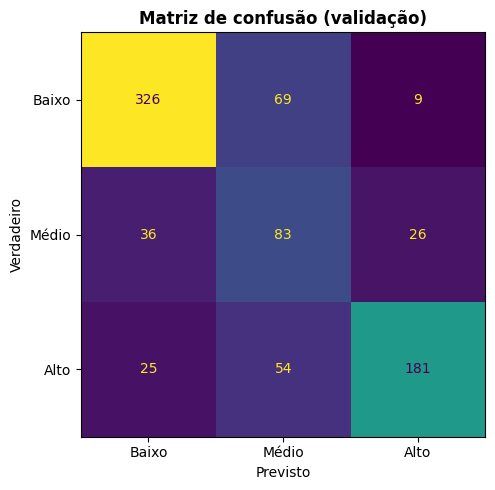


LEITURA DA MATRIZ:
   A diagonal principal concentra as classificações corretas.
   Os elementos fora da diagonal indicam a DIREÇÃO de cada erro.
   Observem a última linha: casos de risco alto classificados como baixo são
   FALSOS NEGATIVOS na classe crítica, e têm custo assimétrico.

              precision    recall  f1-score   support

       Baixo      0.842     0.807     0.824       404
       Médio      0.403     0.572     0.473       145
        Alto      0.838     0.696     0.761       260

    accuracy                          0.729       809
   macro avg      0.694     0.692     0.686       809
weighted avg      0.762     0.729     0.741       809



In [28]:
#@title 🏆 Desempenho na validação { display-mode: "form" }
acuracia = accuracy_score(y_valida, previsoes)
f1 = f1_score(y_valida, previsoes, average="macro")

print("="*60)
print("            DESEMPENHO NO CONJUNTO DE VALIDAÇÃO")
print("="*60)
print(f"  Acurácia ............................. {acuracia*100:5.1f}%")
print(f"  F1-MACRO (métrica oficial) ........... {f1*100:5.1f}%")
print("="*60)
# Faixas calibradas neste conjunto: ~69% e o teto observado com boa configuração.
if   f1 >= .68: print("  Desempenho alto. Verifiquem a estabilidade mudando a validação.")
elif f1 >= .63: print("  Desempenho sólido, com margem de otimização no Bloco 2.")
elif f1 >= .57: print("  Desempenho intermediário. Revisem modelo, profundidade e ZONA LIVRE.")
else:           print("  Desempenho baixo. A configuração atual não captura os padrões.")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_valida, previsoes),
    display_labels=["Baixo","Médio","Alto"]).plot(ax=ax, cmap="viridis", colorbar=False)
ax.set_title("Matriz de confusão (validação)", fontweight="bold")
ax.set_xlabel("Previsto"); ax.set_ylabel("Verdadeiro")
plt.tight_layout(); plt.show()

print("\nLEITURA DA MATRIZ:")
print("   A diagonal principal concentra as classificações corretas.")
print("   Os elementos fora da diagonal indicam a DIREÇÃO de cada erro.")
print("   Observem a última linha: casos de risco alto classificados como baixo são")
print("   FALSOS NEGATIVOS na classe crítica, e têm custo assimétrico.\n")
print(classification_report(y_valida, previsoes,
      target_names=["Baixo","Médio","Alto"], digits=3))

if (previsoes == 1).sum() < 0.05 * len(previsoes):
    print("\n[!] O modelo quase não atribuiu a classe 'Médio'. Isso derruba o F1-macro,")
    print("    que dá peso igual às três classes. Revejam o desbalanceamento do Bloco 1")
    print("    e o parâmetro do Bloco 2 que corrige exatamente esse efeito.")


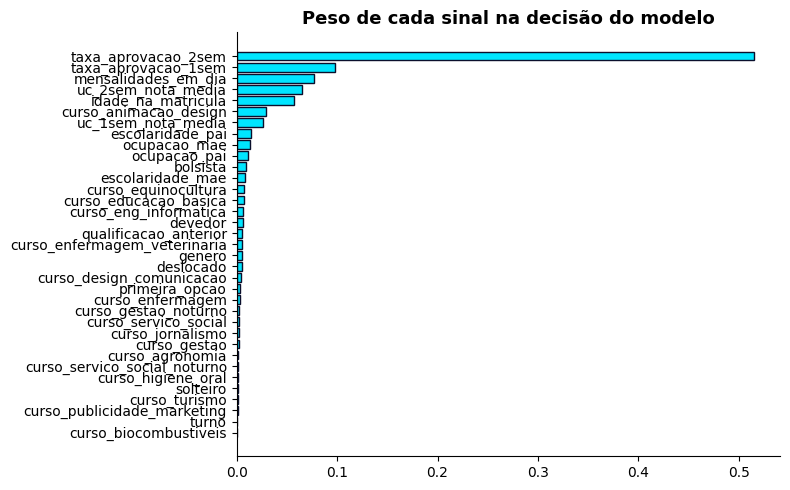

VARIÁVEIS DE MAIOR IMPORTÂNCIA NO MODELO AJUSTADO:

   1. taxa_aprovacao_2sem  (0.515)
   2. taxa_aprovacao_1sem  (0.098)
   3. mensalidades_em_dia  (0.077)

Ressalva necessária: importância de variável NÃO é evidência de causalidade.
O modelo identifica associação estatística. Uma variável pode ranquear alto
por estar correlacionada com um fator não observado que é a causa real.
Confundir as duas coisas é um erro frequente na interpretação de modelos.


In [29]:
#@title 🔦 O que o farol está enxergando? { display-mode: "form" }
# A Marina não quer só o alerta. Ela quer entender por quê.

if hasattr(modelo, "feature_importances_"):
    imp = pd.Series(modelo.feature_importances_, index=X.columns).sort_values()
    titulo = "Peso de cada sinal na decisão do modelo"
else:
    imp = pd.Series(np.abs(modelo.coef_).mean(axis=0), index=X.columns).sort_values()
    titulo = "Peso de cada sinal (média dos coeficientes)"

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color="#00E5FF", edgecolor="#0A0F2C")
ax.set_title(titulo, fontsize=13, fontweight="bold")
ax.spines[["top","right"]].set_visible(False); plt.tight_layout(); plt.show()

top3 = imp.sort_values(ascending=False).head(3)
print("VARIÁVEIS DE MAIOR IMPORTÂNCIA NO MODELO AJUSTADO:\n")
for i, (nome, val) in enumerate(top3.items(), 1):
    print(f"   {i}. {nome}  ({val:.3f})")
print("\nRessalva necessária: importância de variável NÃO é evidência de causalidade.")
print("O modelo identifica associação estatística. Uma variável pode ranquear alto")
print("por estar correlacionada com um fator não observado que é a causa real.")
print("Confundir as duas coisas é um erro frequente na interpretação de modelos.")

---
# 🤔 PARADA OBRIGATÓRIA: uma conversa séria

> **Marina:** *"Antes de fechar, preciso colocar uma questão que não é técnica, mas que
> determina se eu posso ou não usar o que vocês construíram."*
>
> *"O mesmo arquivo que diz 'esse estudante precisa de atenção' também pode ser lido como
> 'esse estudante é um problema'. A saída do modelo é idêntica nos dois casos. O que muda é
> o protocolo institucional em volta dela."*
>
> *"Sistemas de predição de risco aplicados a pessoas produzem um efeito documentado: a
> classificação altera o tratamento, o tratamento altera o resultado, e o resultado acaba
> confirmando a classificação. O modelo passa a validar a si mesmo. Se isso acontecer aqui,
> teremos construído uma profecia, não um diagnóstico."*

### Questões para a equipe deliberar

1. **Sobre o custo assimétrico dos erros.** Um falso positivo consome tempo da equipe
   pedagógica com quem não precisava. Um falso negativo deixa sem apoio quem precisava.
   Qual dos dois vocês priorizariam reduzir, e o que se perde nessa escolha? Note que a
   pergunta não tem resposta técnica: ela depende de um juízo de valor que o modelo não faz.

2. **Sobre variáveis socialmente sensíveis.** Variáveis como `mensalidades_em_dia`,
   `devedor` e `bolsista` costumam aparecer entre as mais relevantes. Elas são, na prática,
   indicadores indiretos de condição socioeconômica — e o mesmo vale para `escolaridade_mae`
   e `ocupacao_pai`. Isso levanta uma questão real da área: um modelo que usa esses
   indicadores aumenta a detecção, mas também concentra a sinalização sobre um grupo já
   vulnerável. Remover a variável resolve o problema ou apenas o torna invisível, já que
   outras variáveis correlacionadas permanecem? **Testem:** retirem essas colunas de `X` no
   Bloco 3, reexecutem e comparem o F1-macro e a matriz de confusão.

3. **Sobre governança.** Que restrições de uso vocês anexariam à entrega? Considerem: quem
   pode acessar a lista, por quanto tempo ela é válida, o que explicitamente não pode ser
   feito com ela, e quem responde por uma decisão tomada com base no modelo.

<img src="https://lh3.googleusercontent.com/d/1tt3Sy_3RapDMyyDio5vU04_moy-o_kuA=w1600" width="100%"
     alt="Farol no alto de uma colina à noite, projetando um feixe dourado sobre um caminho por onde estudantes seguem em direção a uma escola iluminada. Outros permanecem parados no escuro, à margem do feixe.">


In [30]:
#@title 📝 O relatório da sua equipe para a Marina { display-mode: "form" }
nome_da_equipe = "Germinare"  #@param {type:"string"}
#@markdown **1. Por que vocês escolheram esse modelo e essa configuração?**
resposta_1 = "Escolhemos o RandomForest pois ele engloba várias arvores de decisão e faz uma média entre elas, reduzindo a variância de uma única árvore. Além disso a Regressão Logistica possui um viés muito alto se as features não possuirem uma relação alta entre elas. Por fim a configuração de 4 de profundidade se deu por conta de um limite para evitar overfitting e evitando um viés muito alto de colocar 2 por exemplo, enquanto a configuração de 500 árvores é um limiar bom para ser alto assim diminuindo a variancia do resultado final e sem ser tão alto para não diminuir o ganho marginal."  #@param {type:"string"}
#@markdown **2. Quais sinais mais pesam no risco de evasão?**
resposta_2 = "O risco de evasão é mais determinado pelas taxas de aprovação dos dois semestres e as notas médias de ambos semestres também"  #@param {type:"string"}
#@markdown **3. Que restrições de uso vocês anexariam à entrega, e por quê?**
resposta_3 = "Eu recomendaria uma limpeza da base antes, utilizar features como bolsista, genero, ocupação de pai e mãe, escolaridade de pai e mãe é algo que é anti-ético e pode enviesar o modelo."  #@param {type:"string"}

relatorio = {"equipe": nome_da_equipe, "modelo": modelo_escolhido,
             "teste_pct": tamanho_da_validacao, "profundidade": profundidade,
             "f1_macro": round(f1, 4), "acuracia": round(acuracia, 4),
             "just_modelo": resposta_1, "just_sinais": resposta_2,
             "just_cuidado": resposta_3}
faltando = [k for k in ["equipe", "just_modelo", "just_sinais", "just_cuidado"]
            if not relatorio[k].strip()]
if faltando:
    print("⚠️ Ainda faltam campos:", ", ".join(faltando))
else:
    print("Relatório completo. Prossigam para a submissão.")

Relatório completo. Prossigam para a submissão.


In [31]:
from IPython.utils import wildcard
#@title 🚀 Gerar o arquivo de submissão { display-mode: "form" }
#@markdown Rode a célula (▶). Os dois arquivos são baixados automaticamente.
import json, pathlib

PASTA_SUBMISSAO = pathlib.Path("submissoes/tabular")
PASTA_SUBMISSAO.mkdir(parents=True, exist_ok=True)
if "relatorio" not in dir() or not isinstance(relatorio, dict):
    relatorio = {"equipe": "", "modelo": modelo_escolhido,
                 "teste_pct": tamanho_da_validacao, "profundidade": profundidade,
                 "f1_macro": round(f1, 4), "acuracia": round(acuracia, 4),
                 "just_modelo": "", "just_sinais": "", "just_cuidado": ""}

# O modelo é aplicado ao conjunto de teste, cujas respostas ficam com a organização.
# teste_scaler = StandardScaler()
_dados_teste_engenharia = engenharia(dados_teste)
dados_teste = scaler.transform(_dados_teste_engenharia)
palpites = modelo.predict(dados_teste)
# Os ids vêm do próprio arquivo de teste: reinventá-los com arange desalinha a
# submissão do gabarito se a numeração original mudar.
submissao = pd.DataFrame({"id_estudante": IDS_TESTE, "risco_previsto": palpites})

assert len(submissao) == N_TESTE, f"A submissão precisa ter {N_TESTE} linhas."
csv_saida = PASTA_SUBMISSAO / "submissao_tabular.csv"
json_saida = PASTA_SUBMISSAO / "relatorio_tabular.json"
submissao.to_csv(csv_saida, index=False)
with open(json_saida, "w", encoding="utf-8") as f:
    json.dump(relatorio, f, ensure_ascii=False, indent=2)

print("="*60)
print("             ARQUIVOS PRONTOS PARA ENVIO")
print("="*60)
print(f"  submissao_tabular.csv   ({len(submissao)} linhas)")
print("  relatorio_tabular.json")
print("="*60)
print("\n  Distribuição prevista no teste:")
for k, v in pd.Series(palpites).value_counts().sort_index().items():
    print(f"     {NOMES[k]:<6} {v:>4}  ({v/len(palpites)*100:.1f}%)")
display(submissao.head())

try:
    from google.colab import files
    files.download(str(csv_saida))
    files.download(str(json_saida))
    print("\n  Download iniciado. Enviem os dois arquivos na plataforma.")
except ImportError:
    print(f"\n  Fora do Colab: os arquivos estão em {PASTA_SUBMISSAO.resolve()}")

             ARQUIVOS PRONTOS PARA ENVIO
  submissao_tabular.csv   (1078 linhas)
  relatorio_tabular.json

  Distribuição prevista no teste:
     Baixo   502  (46.6%)
     Médio   265  (24.6%)
     Alto    311  (28.8%)


,id_estudante,risco_previsto
0,0,2
1,1,2
2,2,0
3,3,0
4,4,0



  Fora do Colab: os arquivos estão em D:\00 Programacao\OIAA\submissoes\tabular


In [33]:
submissao.to_csv(csv_saida, index=False)
with open(json_saida, "w", encoding="utf-8") as f:
    json.dump(relatorio, f, ensure_ascii=False, indent=2)

---
# 🌟 FIM DA OPERAÇÃO FAROL

> **Marina:** *"Recebi o arquivo e a lista de restrições que vocês anexaram. Levei as duas
> coisas para a reunião pedagógica de segunda."*
>
> *"A discussão que tivemos lá não foi sobre a lista. Foi sobre o que a escola faz com ela,
> e sobre em que ponto a equipe humana entra. Vocês deixaram isso escrito, o que tornou a
> conversa possível."*
>
> *"É um trabalho maduro. Obrigada."*

---

### Competências desenvolvidas neste desafio

- Particionamento entre treino e teste, e a razão estatística por trás dele
- Sobreajuste, subajuste e o compromisso entre viés e variância
- A interface `fit` / `predict` e a lógica de estimadores do `scikit-learn`
- Limitações da acurácia sob desbalanceamento de classes
- Precisão, revocação e a construção do F1-macro
- Leitura direcional da matriz de confusão e custo assimétrico de erros
- Importância de variáveis, e a distinção entre associação e causalidade
- Governança de sistemas preditivos aplicados a pessoas

**Otimização.** Voltem ao Bloco 2 e alterem **um parâmetro por vez**, registrando o efeito
sobre o F1-macro. Variar tudo simultaneamente impede atribuir a melhora a qualquer decisão
específica. Esse método tem nome em experimentação e vale para muito além deste caderno.
